# Task 8: Multi-Metric Correlation Analysis

**Objective:** Compute correlations between numerical variables using three metrics:
- **Pearson** – linear correlation (parametric)
- **Spearman** – rank-based (non-parametric, monotonic)
- **Kendall** – concordance-based (robust to ties & outliers)

Dynamically filter significant pairs and visualize with hierarchical clustering heatmaps.

**Input:** `data/processed/womens_clothing_scaled.csv`

## 1. Setup & Imports

In [3]:
import os
import logging
import warnings
import itertools
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from scipy import stats
from scipy.cluster.hierarchy import dendrogram, linkage
from scipy.spatial.distance import squareform

warnings.filterwarnings('ignore')

# ── Logging setup ──────────────────────────────────────────────────────────────
os.makedirs('../../logs', exist_ok=True)
logging.basicConfig(
    level=logging.INFO,
    format='%(asctime)s | %(levelname)s | %(message)s',
    handlers=[
        logging.FileHandler('../../logs/task_8.log', mode='w'),
        logging.StreamHandler()
    ]
)
logger = logging.getLogger('Task8')
logger.info('Task 8 started.')

# ── Style ───────────────────────────────────────────────────────────────────────
plt.rcParams.update({
    'figure.facecolor': '#0f0f1a',
    'axes.facecolor':   '#1a1a2e',
    'axes.edgecolor':   '#444466',
    'axes.labelcolor':  '#e0e0ff',
    'xtick.color':      '#c0c0e0',
    'ytick.color':      '#c0c0e0',
    'text.color':       '#e0e0ff',
    'grid.color':       '#2a2a4a',
    'grid.linestyle':   '--',
    'font.family':      'DejaVu Sans',
    'font.size':        10,
    'axes.titlesize':   13,
    'axes.titleweight': 'bold',
    'legend.facecolor': '#1a1a2e',
    'legend.edgecolor': '#444466',
})

os.makedirs('../../reports', exist_ok=True)

# ── Parameters ─────────────────────────────────────────────────────────────────
P_VALUE_THRESHOLD  = 0.05    # significance filter
MIN_CORR_THRESHOLD = 0.10    # minimum |r| to include in significant pairs
TOP_N_PAIRS        = 15      # top pairs for bar chart

print('✅ Setup complete.')

2026-11-18 14:34:26,295 | INFO | Task 8 started.


✅ Setup complete.


## 2. Load Data

In [4]:
df = pd.read_csv('../data/processed/womens_clothing_scaled.csv')
logger.info(f'Dataset loaded: {df.shape[0]} rows × {df.shape[1]} columns')
print(f'Shape: {df.shape}')

# Select numerical columns only
num_df = df.select_dtypes(include=[np.number]).copy()

# Drop near-zero-variance columns
low_var = num_df.columns[num_df.std() < 1e-6].tolist()
if low_var:
    num_df.drop(columns=low_var, inplace=True)
    logger.warning(f'Dropped near-zero-variance columns: {low_var}')

num_df.dropna(inplace=True)
print(f'Numerical columns used for correlation ({len(num_df.columns)}): {list(num_df.columns)}')
logger.info(f'Numerical cols: {list(num_df.columns)}')

2026-11-18 14:34:26,329 | INFO | Dataset loaded: 1539 rows × 40 columns
2026-11-18 14:34:26,333 | WARNING | Dropped near-zero-variance columns: ['badges_count', 'inventory_total']
2026-11-18 14:34:26,336 | INFO | Numerical cols: ['price', 'retail_price', 'units_sold', 'rating', 'rating_count', 'rating_five_count', 'rating_four_count', 'rating_three_count', 'rating_two_count', 'rating_one_count', 'product_variation_inventory', 'shipping_option_price', 'countries_shipped_to', 'merchant_rating_count', 'merchant_rating']


Shape: (1539, 40)
Numerical columns used for correlation (15): ['price', 'retail_price', 'units_sold', 'rating', 'rating_count', 'rating_five_count', 'rating_four_count', 'rating_three_count', 'rating_two_count', 'rating_one_count', 'product_variation_inventory', 'shipping_option_price', 'countries_shipped_to', 'merchant_rating_count', 'merchant_rating']


## 3. Compute Correlation Matrices

In [5]:
# ── Pearson ────────────────────────────────────────────────────────────────────
pearson_corr = num_df.corr(method='pearson')

# ── Spearman ───────────────────────────────────────────────────────────────────
spearman_corr = num_df.corr(method='spearman')

# ── Kendall ────────────────────────────────────────────────────────────────────
kendall_corr = num_df.corr(method='kendall')

# ── Save all three matrices ────────────────────────────────────────────────────
pearson_corr.to_csv('../../reports/task_8_pearson_correlation.csv')
spearman_corr.to_csv('../../reports/task_8_spearman_correlation.csv')
kendall_corr.to_csv('../../reports/task_8_kendall_correlation.csv')

logger.info('Correlation matrices computed and saved.')
print('✅ Pearson, Spearman, Kendall matrices computed.')

2026-11-18 14:34:26,615 | INFO | Correlation matrices computed and saved.


✅ Pearson, Spearman, Kendall matrices computed.


## 4. Standard Annotated Heatmaps

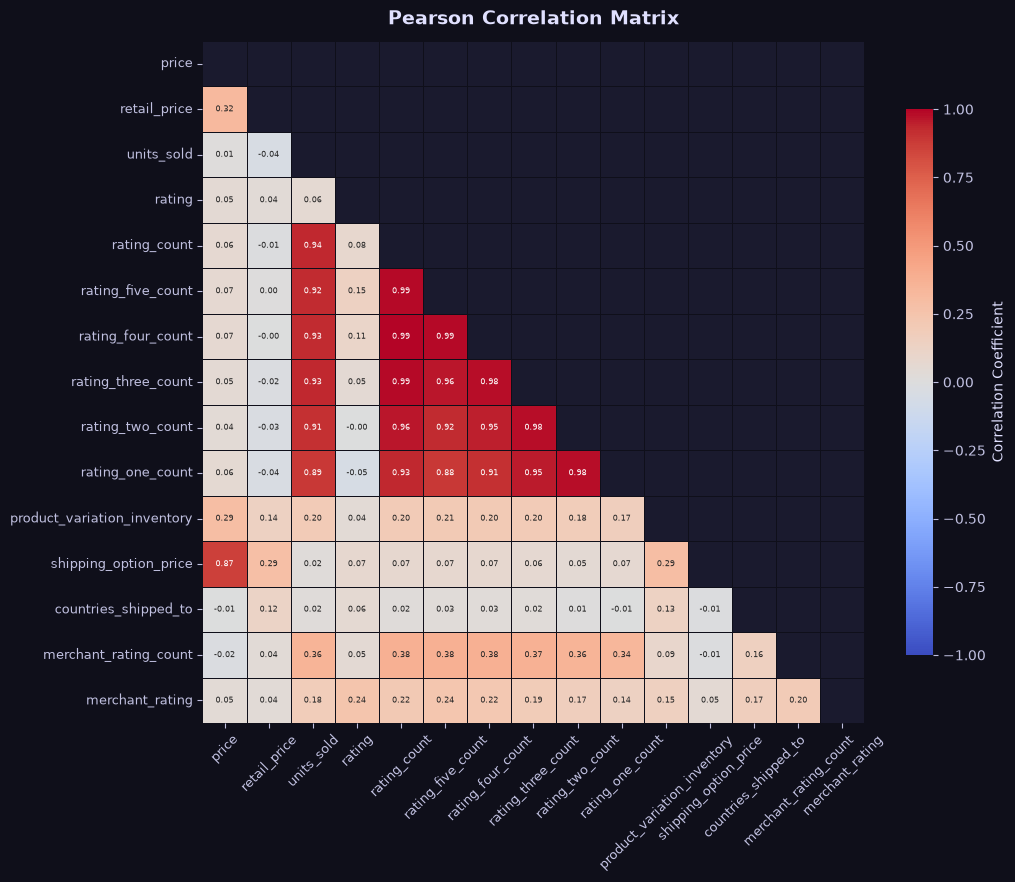

2026-11-18 14:34:28,093 | INFO | Heatmap saved: ../../reports/task_8_heatmap_pearson.png


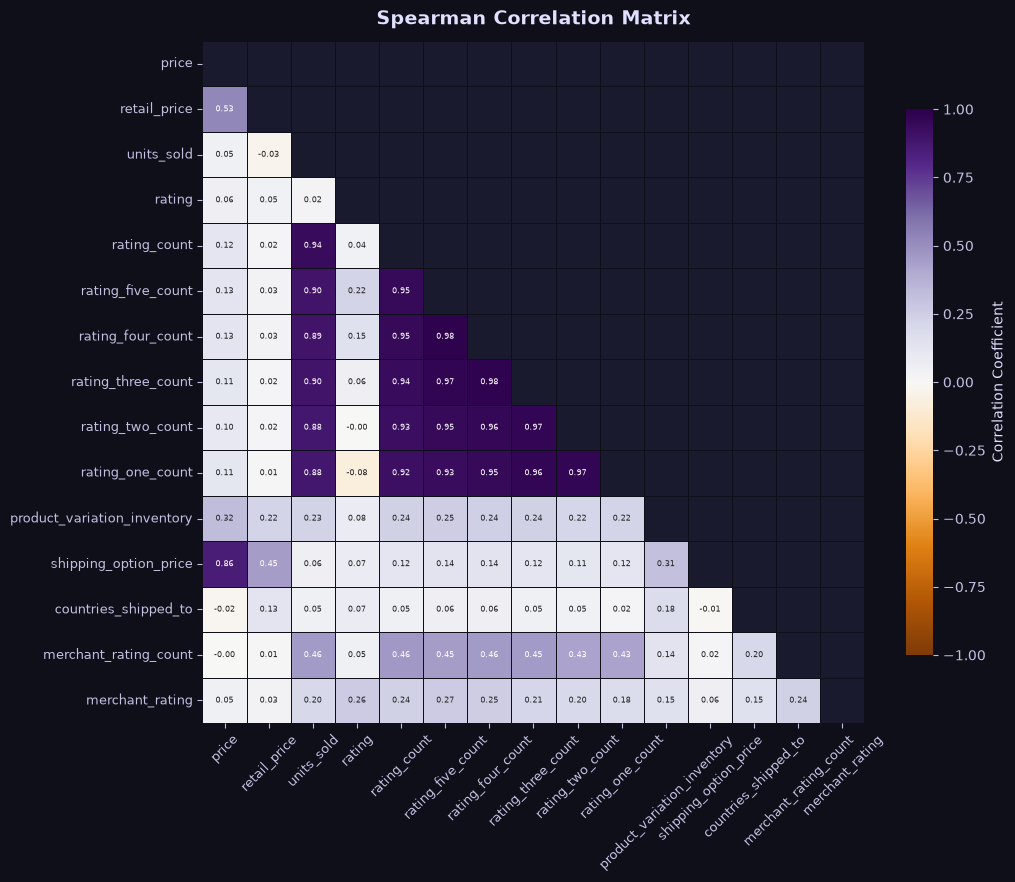

2026-11-18 14:34:29,632 | INFO | Heatmap saved: ../../reports/task_8_heatmap_spearman.png


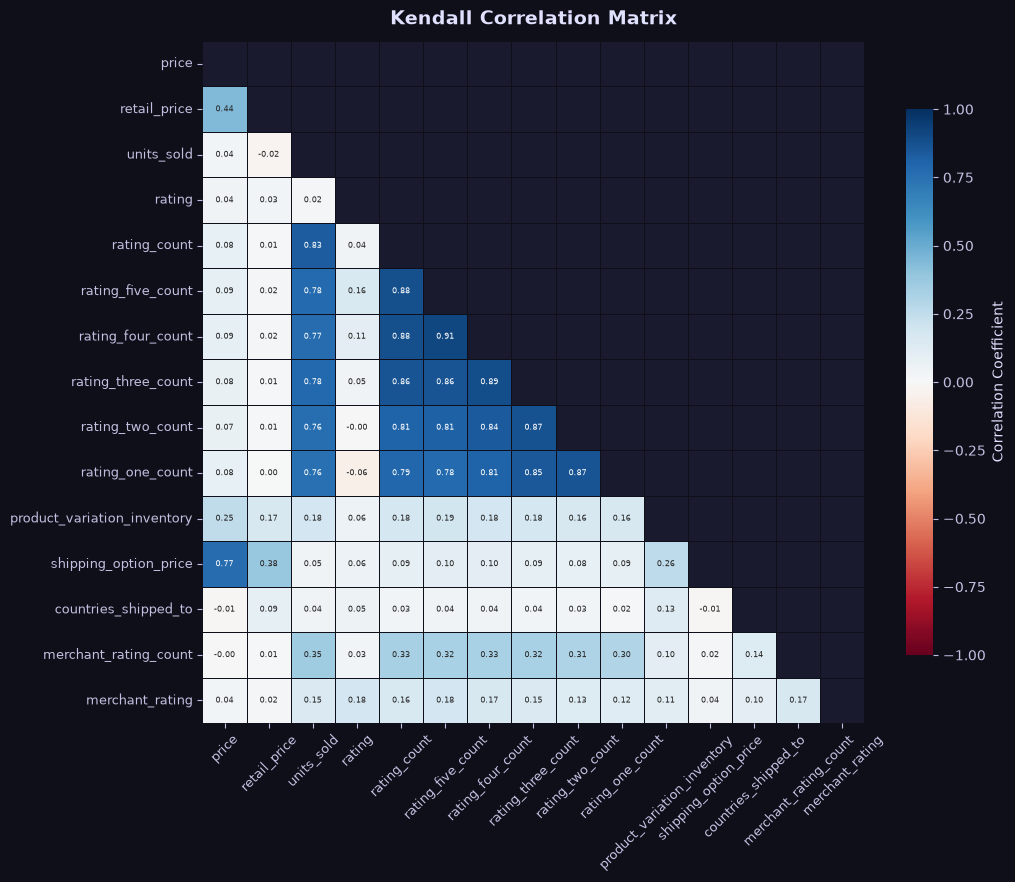

2026-11-18 14:34:31,084 | INFO | Heatmap saved: ../../reports/task_8_heatmap_kendall.png


In [6]:
def plot_corr_heatmap(corr_matrix, title, filename, cmap='coolwarm'):
    """Render an annotated correlation heatmap."""
    n = len(corr_matrix)
    fig_size = max(8, n * 0.7)
    fig, ax = plt.subplots(figsize=(fig_size, fig_size * 0.85))
    fig.patch.set_facecolor('#0f0f1a')

    mask = np.triu(np.ones_like(corr_matrix, dtype=bool))
    np.fill_diagonal(mask, True)

    sns.heatmap(
        corr_matrix,
        mask=mask,
        annot=True,
        fmt='.2f',
        cmap=cmap,
        center=0,
        vmin=-1, vmax=1,
        ax=ax,
        linewidths=0.5,
        linecolor='#0f0f1a',
        annot_kws={'size': max(6, 10 - n // 3)},
        cbar_kws={'label': 'Correlation Coefficient', 'shrink': 0.8}
    )
    ax.set_title(title, fontsize=14, pad=12)
    ax.tick_params(axis='x', rotation=45, labelsize=9)
    ax.tick_params(axis='y', rotation=0,  labelsize=9)

    plt.tight_layout()
    plt.savefig(filename, dpi=150, bbox_inches='tight', facecolor='#0f0f1a')
    plt.show()
    logger.info(f'Heatmap saved: {filename}')

plot_corr_heatmap(pearson_corr,  'Pearson Correlation Matrix',  '../../reports/task_8_heatmap_pearson.png',  'coolwarm')
plot_corr_heatmap(spearman_corr, 'Spearman Correlation Matrix', '../../reports/task_8_heatmap_spearman.png', 'PuOr')
plot_corr_heatmap(kendall_corr,  'Kendall Correlation Matrix',  '../../reports/task_8_heatmap_kendall.png',  'RdBu')

## 5. Hierarchically Clustered Heatmaps (Clustermap)

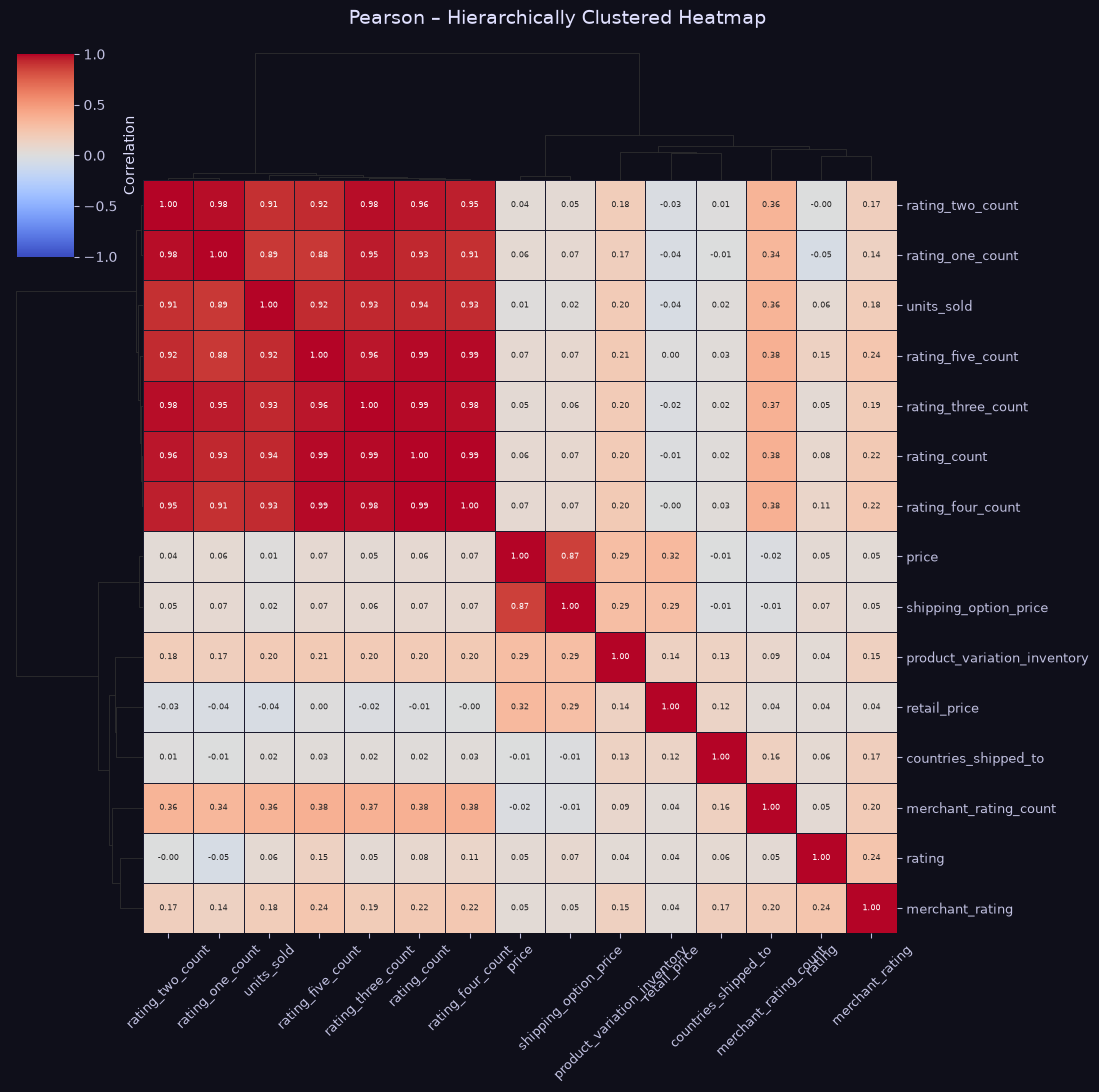

2026-11-18 14:34:33,175 | INFO | Clustermap saved: ../../reports/task_8_clustermap_pearson.png


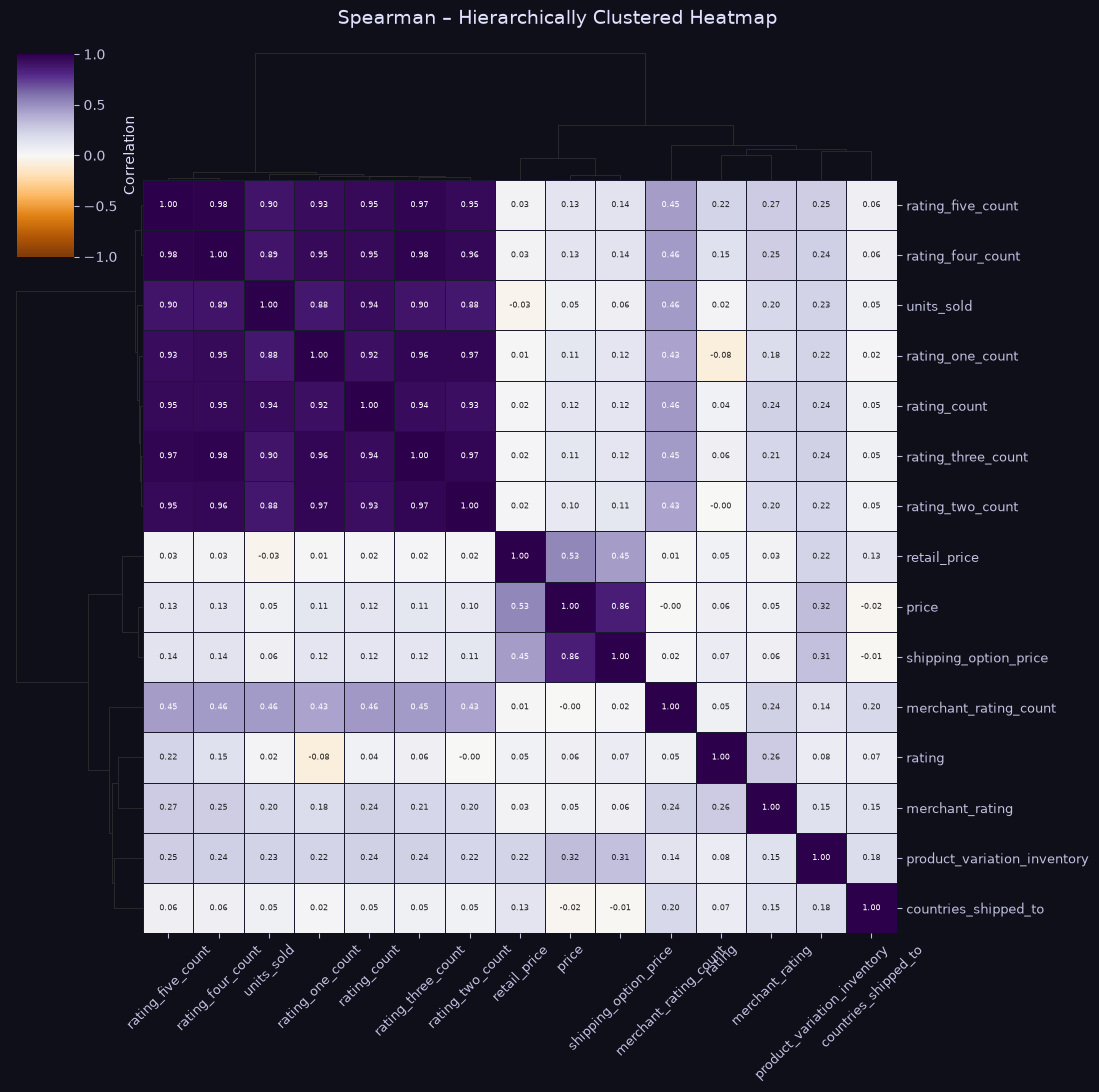

2026-11-18 14:34:35,155 | INFO | Clustermap saved: ../../reports/task_8_clustermap_spearman.png


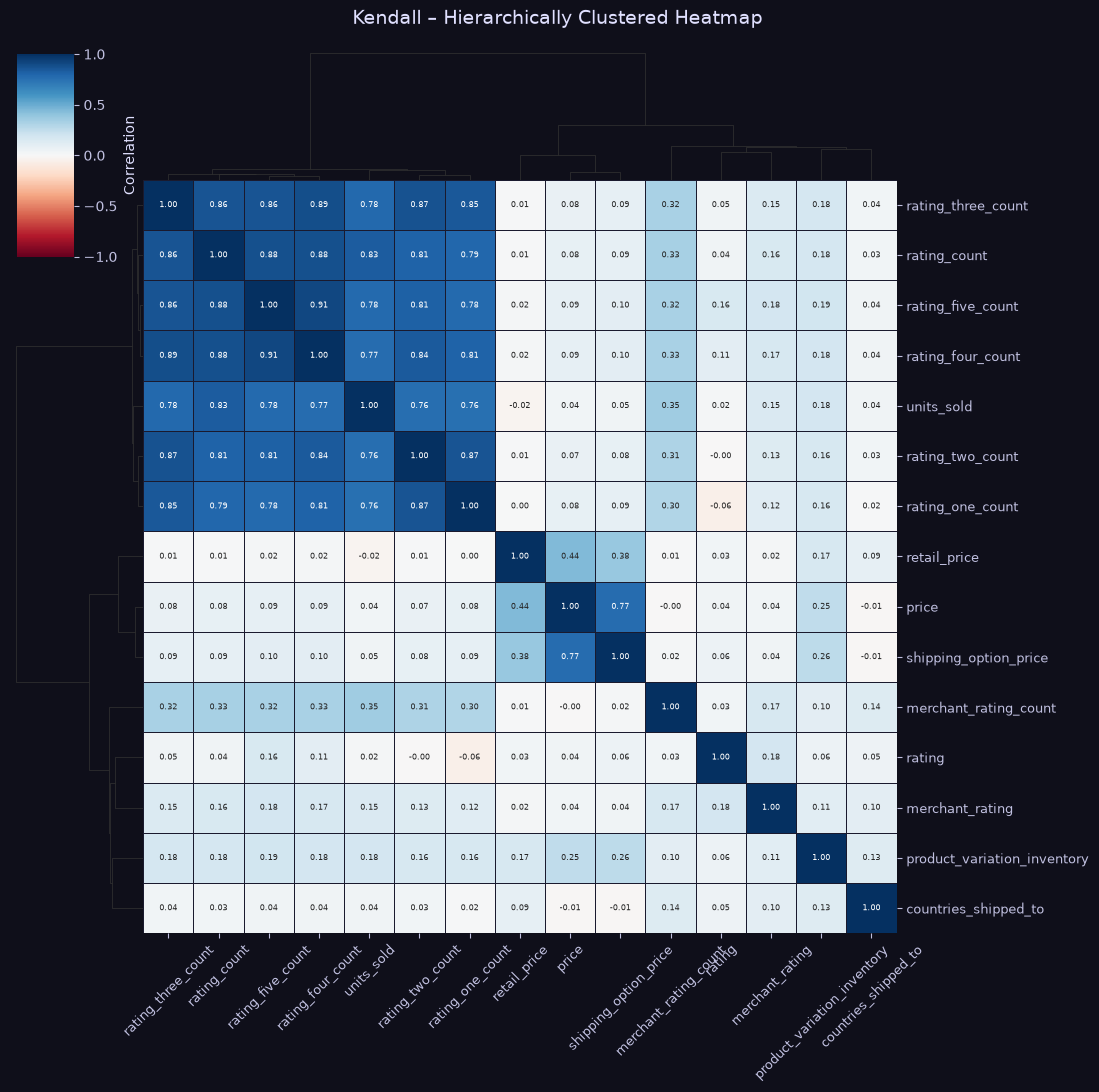

2026-11-18 14:34:37,160 | INFO | Clustermap saved: ../../reports/task_8_clustermap_kendall.png


In [7]:
def plot_clustermap(corr_matrix, title, filename, cmap='coolwarm'):
    """Render a seaborn clustermap with hierarchical clustering."""
    n = len(corr_matrix)
    fig_size = max(8, n * 0.75)

    g = sns.clustermap(
        corr_matrix,
        method='ward',
        metric='euclidean',
        cmap=cmap,
        center=0,
        vmin=-1, vmax=1,
        annot=True,
        fmt='.2f',
        figsize=(fig_size, fig_size),
        linewidths=0.4,
        linecolor='#1a1a2e',
        annot_kws={'size': max(6, 10 - n // 3)},
        cbar_kws={'label': 'Correlation'},
        dendrogram_ratio=0.15,
        colors_ratio=0.02
    )
    g.fig.patch.set_facecolor('#0f0f1a')
    g.ax_heatmap.set_facecolor('#1a1a2e')
    g.fig.suptitle(title, y=1.02, fontsize=14, color='#e0e0ff')
    g.ax_col_dendrogram.set_facecolor('#0f0f1a')
    g.ax_row_dendrogram.set_facecolor('#0f0f1a')
    g.ax_heatmap.tick_params(axis='x', rotation=45, labelsize=9, colors='#c0c0e0')
    g.ax_heatmap.tick_params(axis='y', rotation=0,  labelsize=9, colors='#c0c0e0')

    plt.savefig(filename, dpi=150, bbox_inches='tight', facecolor='#0f0f1a')
    plt.show()
    logger.info(f'Clustermap saved: {filename}')

plot_clustermap(pearson_corr,  'Pearson – Hierarchically Clustered Heatmap',
                '../../reports/task_8_clustermap_pearson.png',  'coolwarm')
plot_clustermap(spearman_corr, 'Spearman – Hierarchically Clustered Heatmap',
                '../../reports/task_8_clustermap_spearman.png', 'PuOr')
plot_clustermap(kendall_corr,  'Kendall – Hierarchically Clustered Heatmap',
                '../../reports/task_8_clustermap_kendall.png',  'RdBu')

## 6. Significance Filtering with P-Value Testing

In [8]:
def compute_pvalue_matrix(data, method='pearson'):
    """Compute p-value matrix for all column pairs."""
    cols = data.columns.tolist()
    p_mat = pd.DataFrame(np.ones((len(cols), len(cols))), index=cols, columns=cols)
    for c1, c2 in itertools.combinations(cols, 2):
        x, y = data[c1].values, data[c2].values
        if method == 'pearson':
            _, p = stats.pearsonr(x, y)
        elif method == 'spearman':
            _, p = stats.spearmanr(x, y)
        elif method == 'kendall':
            _, p = stats.kendalltau(x, y)
        p_mat.loc[c1, c2] = p
        p_mat.loc[c2, c1] = p
    return p_mat

print('Computing p-value matrices (this may take a moment)...')
p_pearson  = compute_pvalue_matrix(num_df, 'pearson')
p_spearman = compute_pvalue_matrix(num_df, 'spearman')
p_kendall  = compute_pvalue_matrix(num_df, 'kendall')
print('✅ P-value matrices computed.')
logger.info('P-value matrices computed.')

Computing p-value matrices (this may take a moment)...


2026-11-18 14:34:37,959 | INFO | P-value matrices computed.


✅ P-value matrices computed.


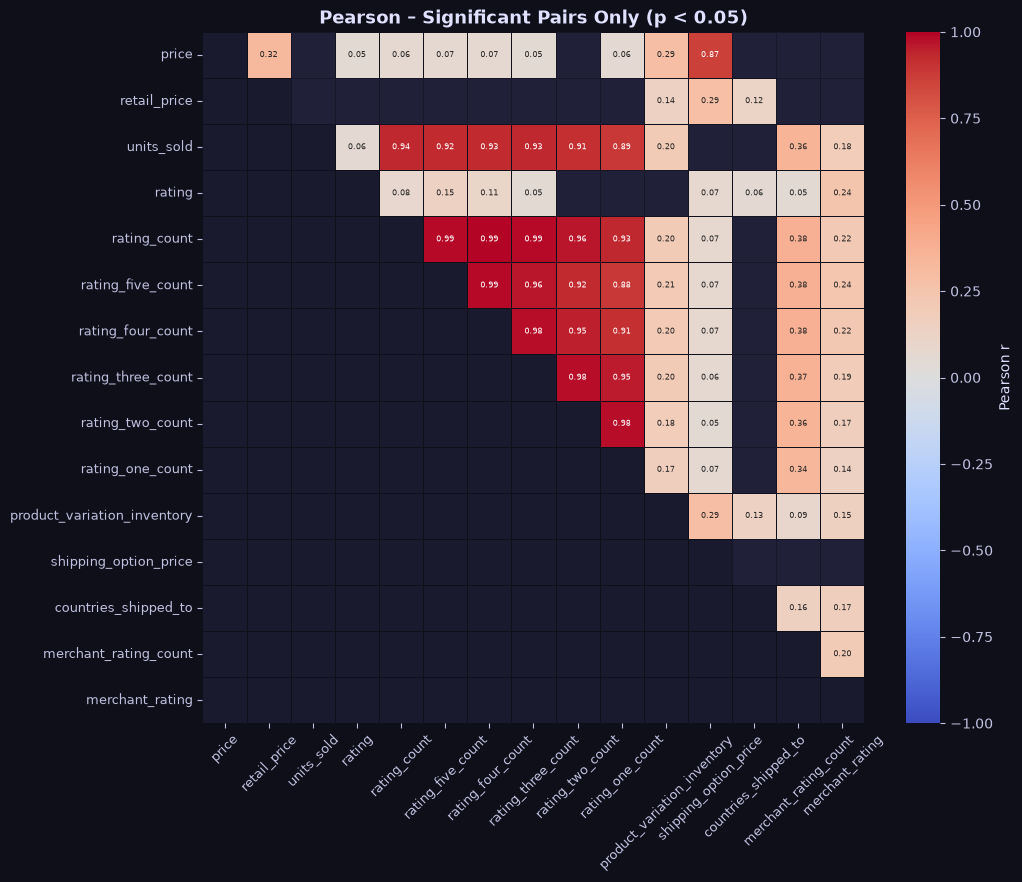

2026-11-18 14:34:40,022 | INFO | Significance-masked heatmap saved.


In [9]:
# ── Significance-masked Pearson heatmap ───────────────────────────────────────
sig_mask = (p_pearson >= P_VALUE_THRESHOLD) | np.eye(len(pearson_corr), dtype=bool)
upper_tri = np.triu(np.ones_like(pearson_corr, dtype=bool), k=1)

n = len(pearson_corr)
fig_size = max(8, n * 0.7)
fig, ax = plt.subplots(figsize=(fig_size, fig_size * 0.85))
fig.patch.set_facecolor('#0f0f1a')

sns.heatmap(pearson_corr, mask=sig_mask | ~upper_tri,
            annot=True, fmt='.2f', cmap='coolwarm',
            center=0, vmin=-1, vmax=1, ax=ax,
            linewidths=0.5, linecolor='#0f0f1a',
            annot_kws={'size': max(6, 10 - n // 3)},
            cbar_kws={'label': 'Pearson r'})
sns.heatmap(pearson_corr, mask=~sig_mask | ~upper_tri,
            annot=False, cmap=['#2a2a4a'],
            center=0, vmin=-1, vmax=1, ax=ax,
            linewidths=0.5, linecolor='#0f0f1a',
            cbar=False, alpha=0.4)

ax.set_title(f'Pearson – Significant Pairs Only (p < {P_VALUE_THRESHOLD})', fontsize=13)
ax.tick_params(axis='x', rotation=45, labelsize=9)
ax.tick_params(axis='y', rotation=0,  labelsize=9)
plt.tight_layout()
plt.savefig('../../reports/task_8_heatmap_significant_pearson.png', dpi=150,
            bbox_inches='tight', facecolor='#0f0f1a')
plt.show()
logger.info('Significance-masked heatmap saved.')

## 7. Significant Pairs Summary Table

In [10]:
def extract_significant_pairs(corr_p, corr_s, corr_k,
                               p_p, p_s, p_k,
                               min_corr=MIN_CORR_THRESHOLD,
                               max_pval=P_VALUE_THRESHOLD):
    """Build a DataFrame of significant variable pairs across all three metrics."""
    cols = corr_p.columns.tolist()
    records = []
    for c1, c2 in itertools.combinations(cols, 2):
        pc, pp = corr_p.loc[c1, c2], p_p.loc[c1, c2]
        sc, sp = corr_s.loc[c1, c2], p_s.loc[c1, c2]
        kc, kp = corr_k.loc[c1, c2], p_k.loc[c1, c2]
        # Include if at least one metric passes both filters
        any_sig = (
            (abs(pc) >= min_corr and pp < max_pval) or
            (abs(sc) >= min_corr and sp < max_pval) or
            (abs(kc) >= min_corr and kp < max_pval)
        )
        if any_sig:
            records.append({
                'Feature_1': c1,
                'Feature_2': c2,
                'Pearson_r':  round(pc, 4),
                'Pearson_p':  round(pp, 4),
                'Spearman_r': round(sc, 4),
                'Spearman_p': round(sp, 4),
                'Kendall_tau': round(kc, 4),
                'Kendall_p':  round(kp, 4),
                'Avg_Abs_Corr': round((abs(pc) + abs(sc) + abs(kc)) / 3, 4)
            })

    return pd.DataFrame(records).sort_values('Avg_Abs_Corr', ascending=False).reset_index(drop=True)

sig_pairs = extract_significant_pairs(
    pearson_corr, spearman_corr, kendall_corr,
    p_pearson, p_spearman, p_kendall
)

sig_pairs.to_csv('../../reports/task_8_significant_pairs.csv', index=False)
logger.info(f'Significant pairs: {len(sig_pairs)} pairs saved.')
print(f'✅ {len(sig_pairs)} significant pairs found.')
display(sig_pairs.head(20))

2026-11-18 14:34:40,063 | INFO | Significant pairs: 70 pairs saved.


✅ 70 significant pairs found.


,Feature_1,Feature_2,Pearson_r,Pearson_p,Spearman_r,Spearman_p,Kendall_tau,Kendall_p,Avg_Abs_Corr
0,rating_five_count,rating_four_count,0.9886,0.0,0.9846,0.0,0.9070,0.0,0.9600
1,rating_four_count,rating_three_count,0.9838,0.0,0.9772,0.0,0.8857,0.0,0.9489
2,rating_count,rating_four_count,0.9947,0.0,0.9500,0.0,0.8826,0.0,0.9424
3,rating_count,rating_five_count,0.9890,0.0,0.9514,0.0,0.8811,0.0,0.9405
4,rating_three_count,rating_two_count,0.9812,0.0,0.9681,0.0,0.8719,0.0,0.9404
5,rating_two_count,rating_one_count,0.9818,0.0,0.9662,0.0,0.8654,0.0,0.9378
6,rating_five_count,rating_three_count,0.9644,0.0,0.9701,0.0,0.8599,0.0,0.9315
7,rating_count,rating_three_count,0.9884,0.0,0.9445,0.0,0.8604,0.0,0.9311
8,rating_three_count,rating_one_count,0.9547,0.0,0.9646,0.0,0.8514,0.0,0.9236
9,rating_four_count,rating_two_count,0.9502,0.0,0.9596,0.0,0.8410,0.0,0.9169


## 8. Top Correlations Bar Chart

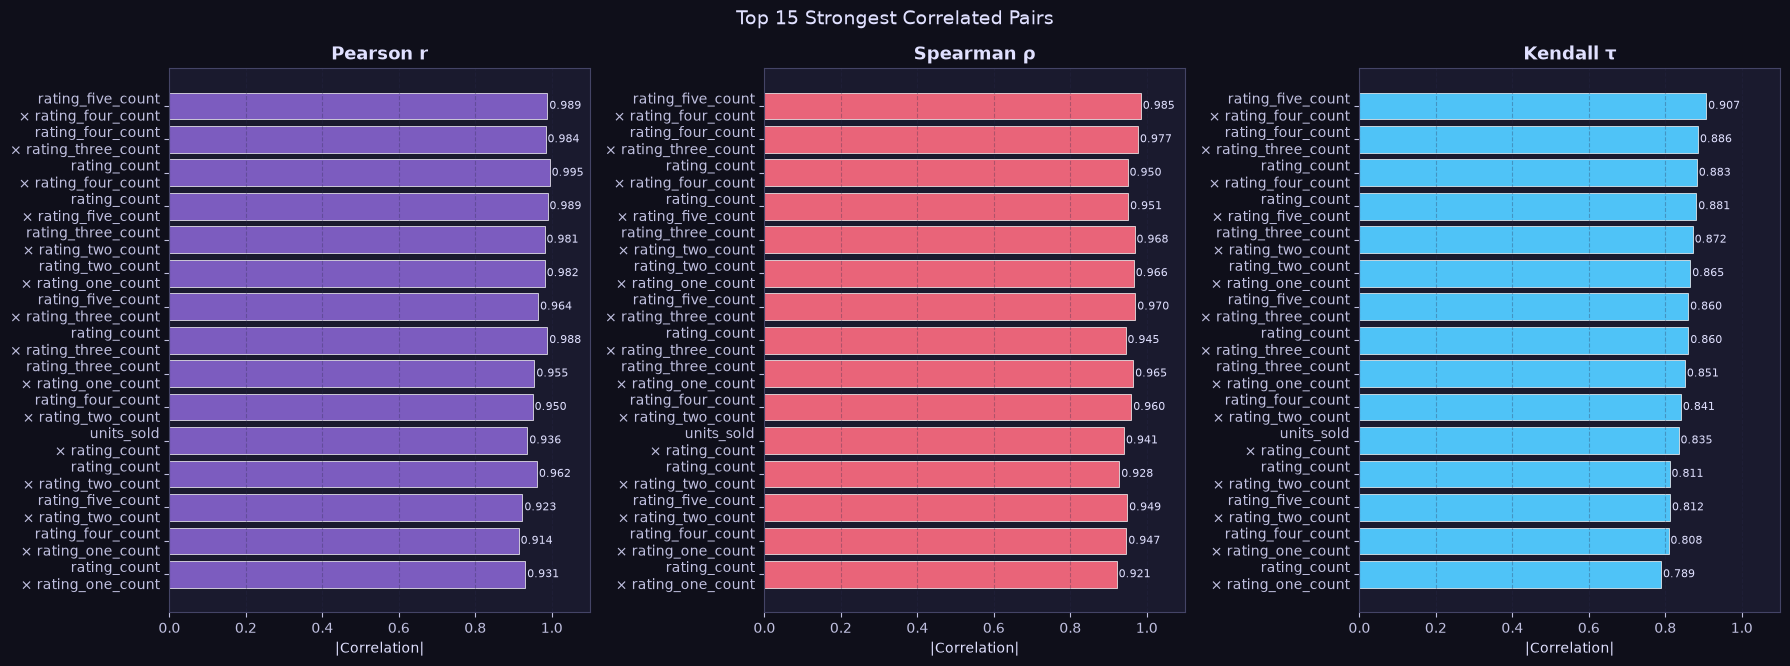

2026-11-18 14:34:42,476 | INFO | Top correlations bar chart saved.


In [11]:
if not sig_pairs.empty:
    top = sig_pairs.head(TOP_N_PAIRS).copy()
    top['Pair'] = top['Feature_1'] + '\n× ' + top['Feature_2']

    fig, axes = plt.subplots(1, 3, figsize=(18, max(5, len(top) * 0.45)))
    fig.suptitle(f'Top {TOP_N_PAIRS} Strongest Correlated Pairs', fontsize=14, color='#e0e0ff')

    metric_info = [
        ('Pearson_r',   '#7c5cbf', 'Pearson r'),
        ('Spearman_r',  '#e96479', 'Spearman ρ'),
        ('Kendall_tau', '#4fc3f7', 'Kendall τ'),
    ]

    for ax, (col, color, label) in zip(axes, metric_info):
        bar_colors = [color if v >= 0 else '#f5a623' for v in top[col]]
        ax.barh(top['Pair'], top[col].abs(), color=bar_colors,
                edgecolor='white', linewidth=0.5)
        for i, (v, pair) in enumerate(zip(top[col], top['Pair'])):
            ax.text(abs(v) + 0.005, i, f'{v:.3f}', va='center', fontsize=8, color='#e0e0ff')
        ax.set_xlim(0, 1.1)
        ax.set_title(label); ax.set_xlabel('|Correlation|')
        ax.invert_yaxis()
        ax.xaxis.grid(True, alpha=0.3)

    plt.tight_layout()
    plt.savefig('../../reports/task_8_top_correlations_bar.png', dpi=150,
                bbox_inches='tight', facecolor='#0f0f1a')
    plt.show()
    logger.info('Top correlations bar chart saved.')

## 9. Pairplot for Top Correlated Features

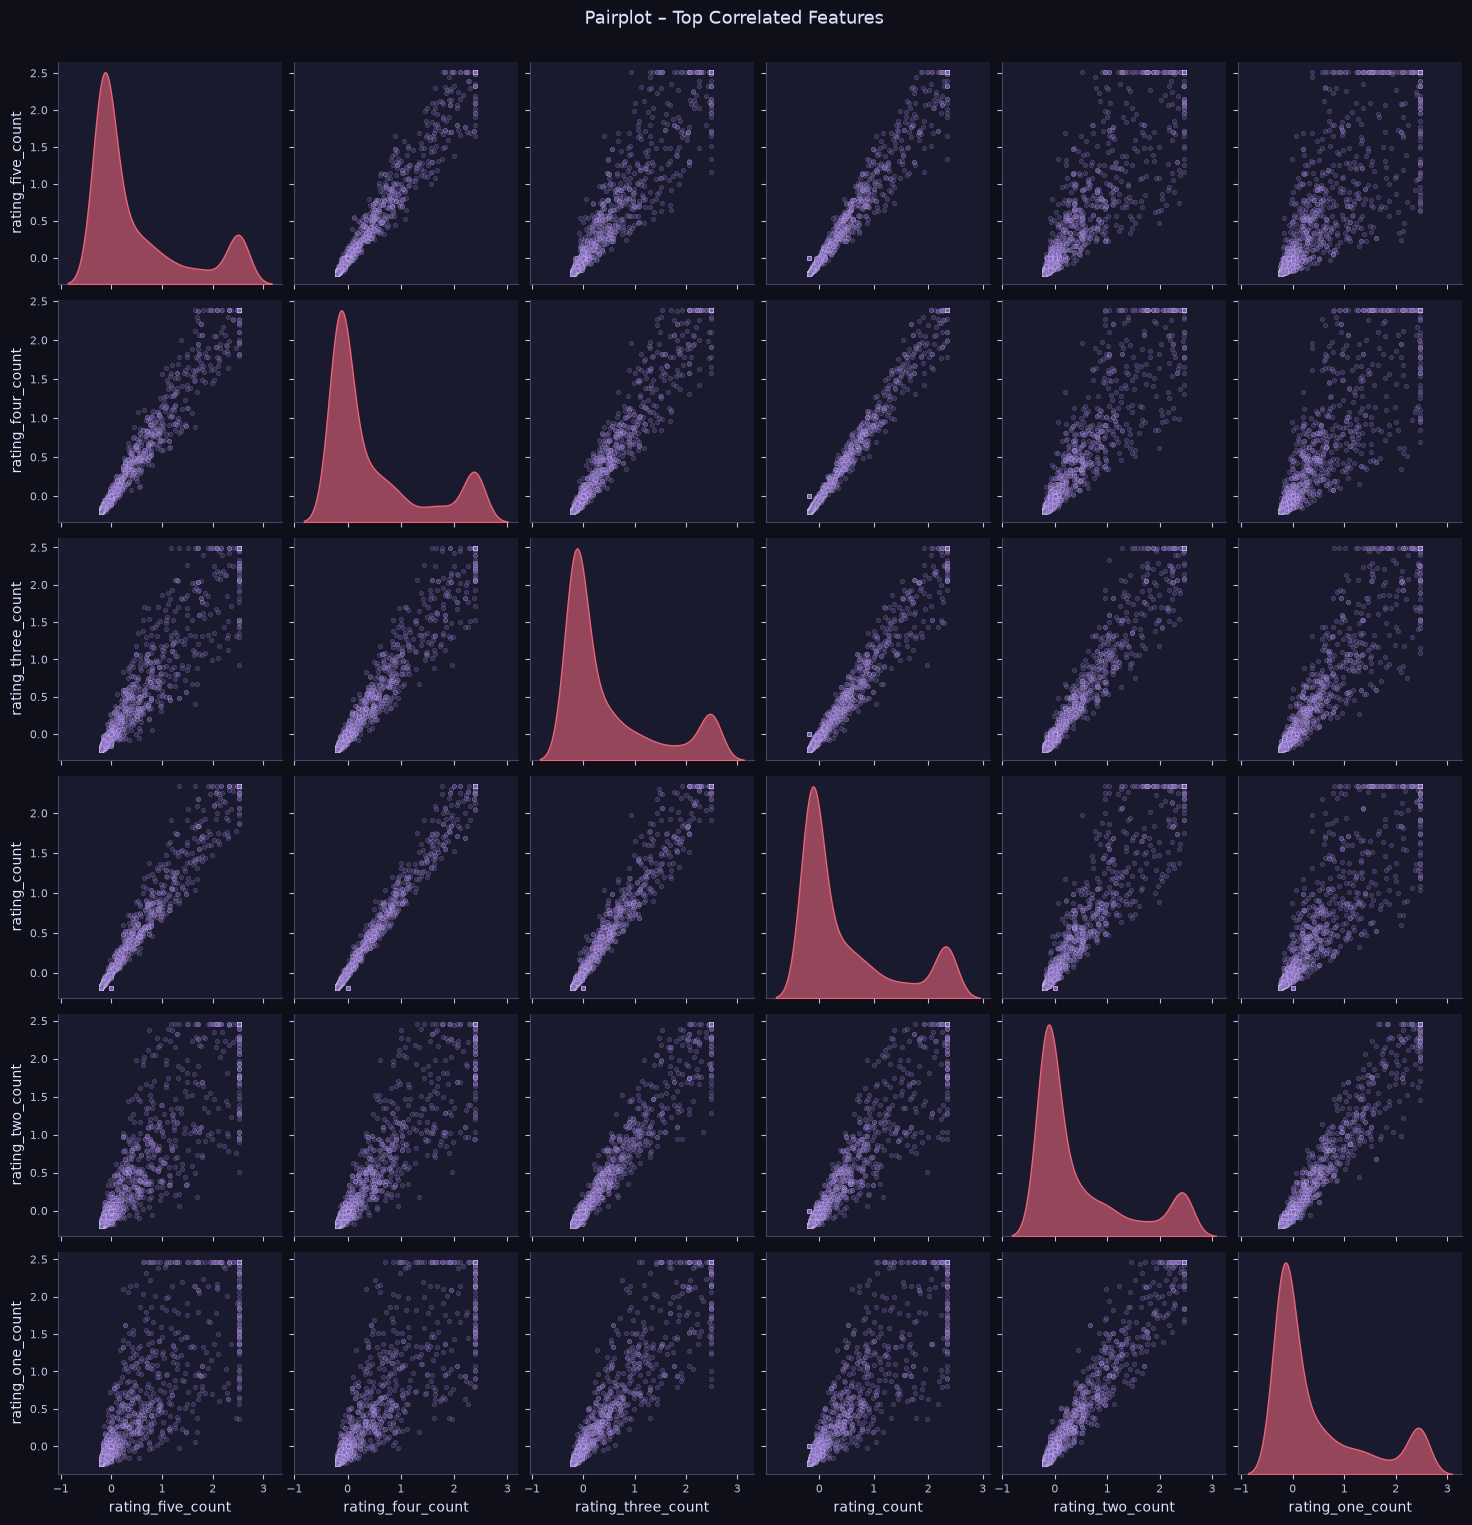

2026-11-18 14:34:47,576 | INFO | Pairplot saved.


In [12]:
if not sig_pairs.empty:
    # Collect unique features from top pairs
    top_features = []
    for _, row in sig_pairs.head(6).iterrows():
        if row['Feature_1'] not in top_features:
            top_features.append(row['Feature_1'])
        if row['Feature_2'] not in top_features:
            top_features.append(row['Feature_2'])
    top_features = top_features[:6]  # max 6 for readability

    sample = num_df[top_features].sample(min(2000, len(num_df)), random_state=42)

    g = sns.pairplot(
        sample,
        diag_kind='kde',
        plot_kws={'alpha': 0.3, 'color': '#7c5cbf', 's': 10},
        diag_kws={'color': '#e96479', 'fill': True, 'alpha': 0.6}
    )
    g.fig.patch.set_facecolor('#0f0f1a')
    for ax in g.axes.ravel():
        ax.set_facecolor('#1a1a2e')
        ax.tick_params(colors='#c0c0e0', labelsize=8)
        ax.xaxis.label.set_color('#e0e0ff')
        ax.yaxis.label.set_color('#e0e0ff')

    g.fig.suptitle('Pairplot – Top Correlated Features', y=1.02, fontsize=13, color='#e0e0ff')
    plt.savefig('../../reports/task_8_pairplot.png', dpi=120,
                bbox_inches='tight', facecolor='#0f0f1a')
    plt.show()
    logger.info('Pairplot saved.')

## 10. Metric Comparison – Side-by-Side Scatter

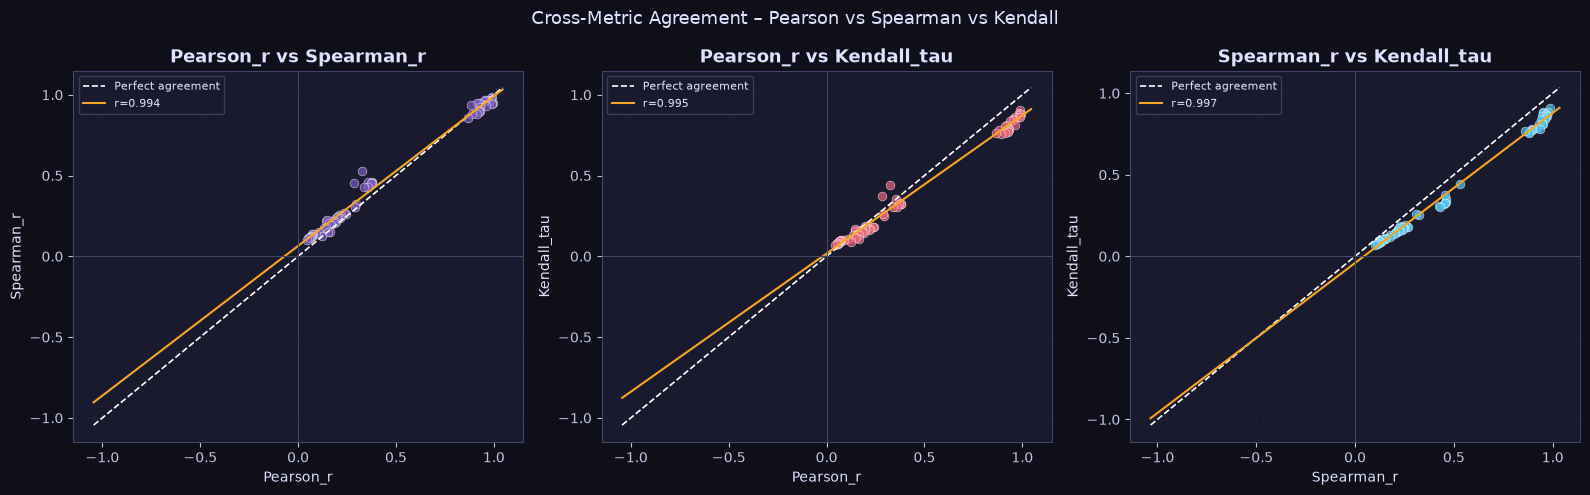

2026-11-18 14:34:48,632 | INFO | Metric comparison scatter saved.
2026-11-18 14:34:48,632 | INFO | Task 8 complete.


✅ Task 8 complete. All correlation matrices and plots saved to reports/ folder.


In [13]:
# Compare how the three metrics agree with each other
if not sig_pairs.empty:
    fig, axes = plt.subplots(1, 3, figsize=(16, 5))
    fig.suptitle('Cross-Metric Agreement – Pearson vs Spearman vs Kendall', fontsize=13, color='#e0e0ff')

    pairs_data = [
        ('Pearson_r', 'Spearman_r',  axes[0], '#7c5cbf'),
        ('Pearson_r', 'Kendall_tau', axes[1], '#e96479'),
        ('Spearman_r','Kendall_tau', axes[2], '#4fc3f7'),
    ]
    for x_col, y_col, ax, color in pairs_data:
        x, y = sig_pairs[x_col].values, sig_pairs[y_col].values
        ax.scatter(x, y, color=color, alpha=0.7, s=40, edgecolors='white', linewidth=0.4)
        # Perfect agreement line
        lim = max(abs(x).max(), abs(y).max()) + 0.05
        ax.plot([-lim, lim], [-lim, lim], 'w--', linewidth=1.2, label='Perfect agreement')
        # Regression line
        m, b, r, _, _ = stats.linregress(x, y)
        xfit = np.linspace(-lim, lim, 100)
        ax.plot(xfit, m*xfit + b, color='#f5a623', linewidth=1.5,
                label=f'r={r:.3f}')
        ax.set_xlabel(x_col); ax.set_ylabel(y_col)
        ax.set_title(f'{x_col} vs {y_col}')
        ax.axhline(0, color='#444466', linewidth=0.8)
        ax.axvline(0, color='#444466', linewidth=0.8)
        ax.legend(fontsize=8)
        ax.yaxis.grid(True, alpha=0.3); ax.xaxis.grid(True, alpha=0.3)

    plt.tight_layout()
    plt.savefig('../../reports/task_8_metric_comparison.png', dpi=150,
                bbox_inches='tight', facecolor='#0f0f1a')
    plt.show()
    logger.info('Metric comparison scatter saved.')

logger.info('Task 8 complete.')
print('✅ Task 8 complete. All correlation matrices and plots saved to reports/ folder.')